Import the modules that will be used.

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [3]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

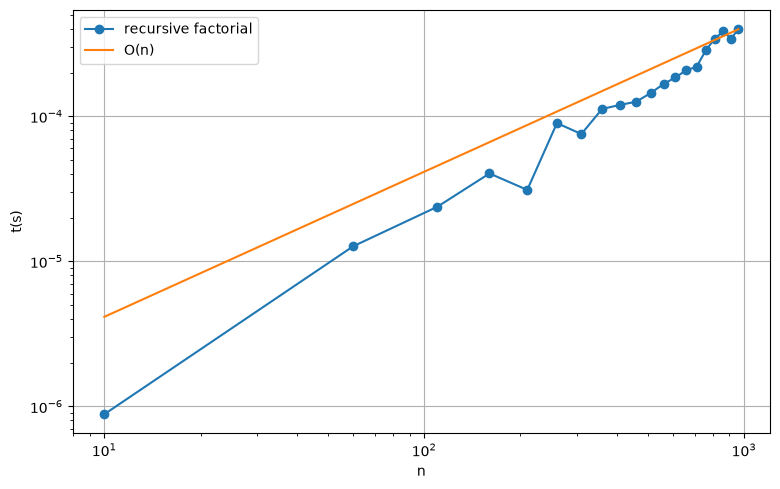

In [16]:
%matplotlib inline
import sys
import numpy as np
import matplotlib.pyplot as plt


sys.setrecursionlimit(3000)
N = np.arange(10, 1001, 50)
times = []


for n in N:
    t = %timeit -q -n5 -r3 -o factorial(int(n))
    
    times.append(t.best)

scale_factor = times[-1] / N[-1]
plt.figure(figsize=(9, 5.5))


plt.loglog(N, times, marker='o',label='recursive factorial')
plt.xlabel('n')
plt.ylabel('t(s)')

plt.loglog(N, scale_factor*N, label='O(n)')
plt.legend()
plt.grid()
plt.show()



## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [ ]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [ ]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [12]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

N = 2**np.arange(2, 12)

times = []

for n in N:
    
    A = np.random.rand(n, n)
    t = %timeit -q -n2 -r2 -o np.linalg.slogdet(A)
    times.append(t.best)

Plot result:

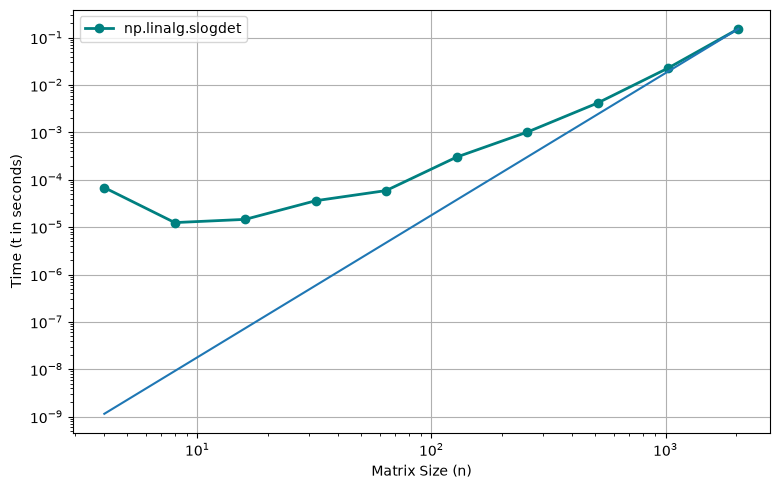

In [15]:
plt.figure(figsize=(9, 5.5))

plt.loglog(N, times, marker='o', color='teal', lw=2, label='np.linalg.slogdet')
plt.xlabel('Matrix Size (n)')
plt.ylabel('Time (t in seconds)')


scale_factor = times[-1] / (N[-1]**3)
plt.loglog(N, scale_factor*(N**3))

plt.grid()
plt.legend(loc='upper left')

plt.show()
